In [1]:
import pickle
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [2]:
# Load data.pkl
with open('data.pkl', 'rb') as f:
    data = pickle.load(f)

# Load data.pkl
with open('splits/split.pkl', 'rb') as f:
    split = pickle.load(f)

# Load feat_dict.pkl
with open('feat_dict.pkl', 'rb') as f:
    feat_dict = pickle.load(f)

# Display types and basic info
type(data), type(split), type(feat_dict), len(data) if hasattr(data, '__len__') else None, len(split) if hasattr(split, '__len__') else None, len(feat_dict) if hasattr(feat_dict, '__len__') else None

(list, dict, dict, 9847, 3, 6)

In [4]:
print("Data:", data[1])
print("Feature Dictionary:", feat_dict)
print(data[1].pos_N_3_I.shape)

Data: Data(edge_index=[2, 14], atom_type_N=[7], r_feat_N_Z=[7, 21], p_feat_N_Z=[7, 21], pos_N_3_I=[7, 3, 10], r_edge_index=[2, 14], p_edge_index=[2, 10], edge_type=[14], rdmol=[2], smiles='[o:1]1[c:2]([H:6])[n:3][n:4][c:5]1[H:7]>>[N:3]#[N:4].[O+:1](=[C-:2][H:6])[C:5][H:7]', r_index_to_mapnum=[7], p_index_to_mapnum=[7], mapnum_to_r_index=[7], mapnum_to_p_index=[7], augmented=False, rxn_index='rxn2092')
Feature Dictionary: {'GetIsAromatic': {True: 0, False: 1}, 'GetFormalCharge': {0: 0, 1: 1, -1: 2}, 'GetHybridization': {rdkit.Chem.rdchem.HybridizationType(3): 0, rdkit.Chem.rdchem.HybridizationType(1): 1, rdkit.Chem.rdchem.HybridizationType(2): 2, rdkit.Chem.rdchem.HybridizationType(4): 3}, 'GetTotalValence': {2: 0, 4: 1, 3: 2, 1: 3, 0: 4}, 'GetTotalDegree': {2: 0, 3: 1, 1: 2, 4: 3, 0: 4}, 'IsInRing': {True: 0, False: 1}}
torch.Size([7, 3, 10])


In [7]:
print("Split", split.keys())

Split dict_keys(['train', 'val', 'test'])


In [9]:
pos = data[400].pos_N_3_I
print("Position shape:", pos.shape)
print("Neb images:", pos[3])
print("Neb images:", pos[3][1])
print("All positions", pos)

Position shape: torch.Size([8, 3, 10])
Neb images: tensor([[-0.9828, -0.9698, -0.9605, -0.9390, -0.9109, -0.8803, -0.8504, -0.8231,
         -0.7981, -0.7682],
        [-0.4011, -0.4068, -0.4042, -0.3955, -0.3930, -0.3972, -0.3967, -0.3933,
         -0.3897, -0.3806],
        [-0.0928, -0.1034, -0.1236, -0.1374, -0.1490, -0.1586, -0.1644, -0.1667,
         -0.1653, -0.1602]])
Neb images: tensor([-0.4011, -0.4068, -0.4042, -0.3955, -0.3930, -0.3972, -0.3967, -0.3933,
        -0.3897, -0.3806])
All positions tensor([[[ 2.4295,  2.3886,  2.3968,  2.4082,  2.4178,  2.4278,  2.4400,
           2.4555,  2.4681,  2.4511],
         [-0.1801, -0.2307, -0.2304, -0.2286, -0.2251, -0.2211, -0.2189,
          -0.2256, -0.2606, -0.3376],
         [ 0.9903,  1.0313,  1.0643,  1.0828,  1.0970,  1.1075,  1.1265,
           1.1516,  1.1750,  1.2065]],

        [[ 1.4476,  1.4492,  1.4788,  1.4953,  1.5025,  1.5042,  1.5171,
           1.5417,  1.5643,  1.5709],
         [ 0.0851,  0.0646,  0.0113, -0.02

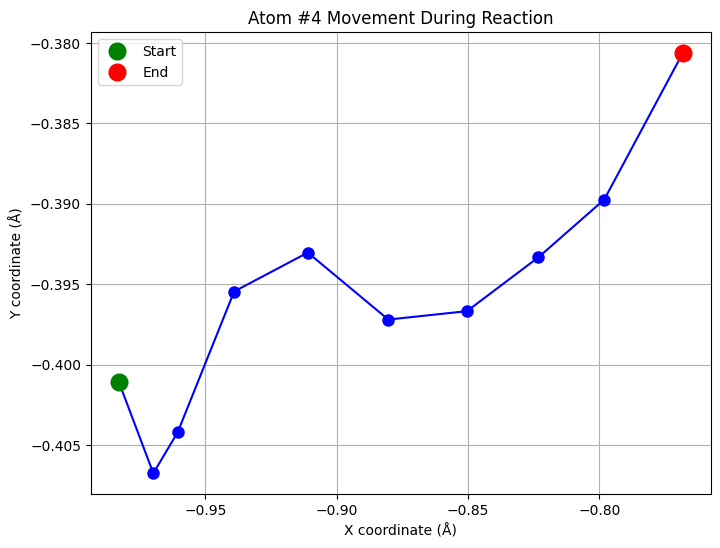

In [11]:
# Get 4th atom's trajectory
atom_4_traj = data[400].pos_N_3_I[3]  # [3, 10]
x_coords = atom_4_traj[0]  # x across 10 images
y_coords = atom_4_traj[1]  # y across 10 images
z_coords = atom_4_traj[2]  # z across 10 images

# Plot 2D trajectory (x vs y)
plt.figure(figsize=(8, 6))
plt.plot(x_coords, y_coords, 'bo-', markersize=8)
plt.plot(x_coords[0], y_coords[0], 'go', markersize=12, label='Start')
plt.plot(x_coords[-1], y_coords[-1], 'ro', markersize=12, label='End')
plt.xlabel('X coordinate (Å)')
plt.ylabel('Y coordinate (Å)')
plt.title('Atom #4 Movement During Reaction')
plt.legend()
plt.grid(True)
plt.show()

# print(f"Total displacement: {torch.norm(atom_4_traj[:, -1] - atom_4_traj[:, 0]):.3f} Å")

In [12]:
# Pick a reaction (e.g., entry 400)
reaction_idx = 400
reaction_data = data[reaction_idx]

# Extract NEB trajectory
pos_N_3_I = reaction_data.pos_N_3_I  # [atoms, 3, images]
num_atoms, _, num_images = pos_N_3_I.shape

print(f"Reaction {reaction_idx}:")
print(f"Number of atoms: {num_atoms}")
print(f"Number of NEB images: {num_images}")
print(f"SMILES: {reaction_data.smiles}")

# Convert to numpy for easier manipulation
neb_trajectory = pos_N_3_I.numpy()  # [atoms, 3, images]

# Reshape to [images, atoms, 3] for easier iteration
neb_images = neb_trajectory.transpose(2, 0, 1)  # [images, atoms, 3]

print(f"NEB images shape: {neb_images.shape}")

Reaction 400:
Number of atoms: 8
Number of NEB images: 10
SMILES: [N:1]#[C:2][C@@:3]1([H:6])[C:4]([H:7])([H:8])[O:5]1>>[N-:1]=[C:2]=[C+:3][C:4]([O:5][H:6])([H:7])[H:8]
NEB images shape: (10, 8, 3)


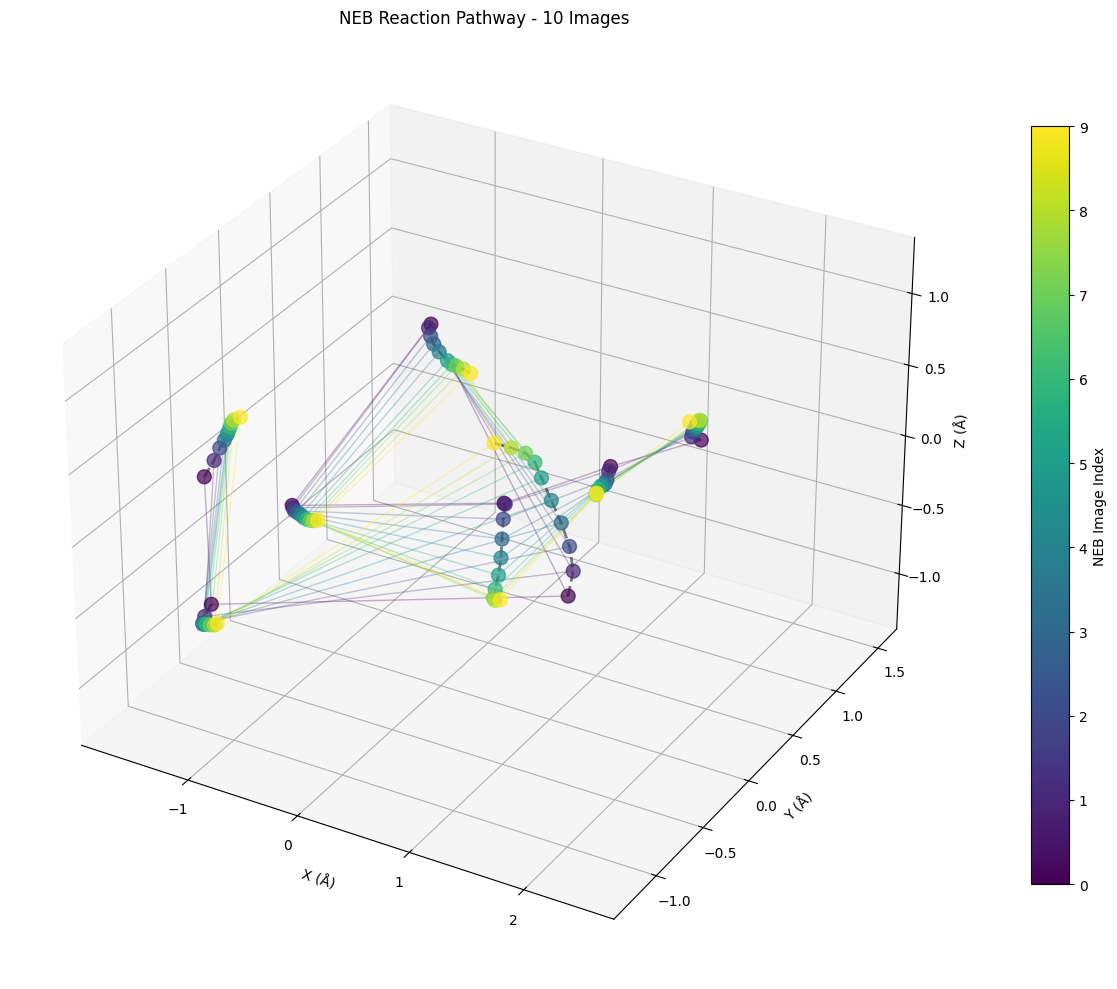

In [13]:
def plot_neb_trajectory_3d(neb_images, atom_types=None, save_path=None):
    """
    Plot all NEB images in a 3D trajectory
    """
    num_images, num_atoms, _ = neb_images.shape
    
    fig = plt.figure(figsize=(15, 10))
    ax = fig.add_subplot(111, projection='3d')
    
    # Color map for different NEB images
    colors = plt.cm.viridis(np.linspace(0, 1, num_images))
    
    for img_idx in range(num_images):
        positions = neb_images[img_idx]  # [atoms, 3]
        
        # Plot atoms as points
        ax.scatter(positions[:, 0], positions[:, 1], positions[:, 2], 
                  c=[colors[img_idx]], s=100, alpha=0.7, 
                  label=f'Image {img_idx}')
        
        # Connect atoms with bonds (simple - connect consecutive atoms)
        for atom_idx in range(num_atoms-1):
            ax.plot([positions[atom_idx, 0], positions[atom_idx+1, 0]],
                   [positions[atom_idx, 1], positions[atom_idx+1, 1]], 
                   [positions[atom_idx, 2], positions[atom_idx+1, 2]],
                   c=colors[img_idx], alpha=0.3, linewidth=1)
    
    # Draw trajectory lines for each atom
    for atom_idx in range(num_atoms):
        atom_traj = neb_images[:, atom_idx, :]  # [images, 3]
        ax.plot(atom_traj[:, 0], atom_traj[:, 1], atom_traj[:, 2], 
               'k--', alpha=0.5, linewidth=2)
    
    ax.set_xlabel('X (Å)')
    ax.set_ylabel('Y (Å)')
    ax.set_zlabel('Z (Å)')
    ax.set_title(f'NEB Reaction Pathway - {num_images} Images')
    
    # Add colorbar
    sm = plt.cm.ScalarMappable(cmap='viridis', norm=plt.Normalize(vmin=0, vmax=num_images-1))
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax, shrink=0.8, aspect=20)
    cbar.set_label('NEB Image Index')
    
    # if save_path:
        # plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    plt.tight_layout()
    return fig, ax

# Create the visualization
fig, ax = plot_neb_trajectory_3d(neb_images, save_path='neb_trajectory_3d.png')
plt.show()

In [14]:
def save_individual_neb_images(neb_images, reaction_data, output_dir='neb_snapshots'):
    """
    Save each NEB image as individual XYZ file for external visualization
    """
    import os
    os.makedirs(output_dir, exist_ok=True)
    
    num_images, num_atoms, _ = neb_images.shape
    
    # Get atom types if available
    if hasattr(reaction_data, 'atom_type'):
        atom_types = reaction_data.atom_type.numpy()
        # Convert atom type indices to element symbols (you might need to adjust this)
        element_map = {1: 'H', 6: 'C', 7: 'N', 8: 'O', 16: 'S'}  # Add more as needed
        elements = [element_map.get(at, 'X') for at in atom_types]
    else:
        elements = ['C'] * num_atoms  # Default to carbon
    
    for img_idx in range(num_images):
        xyz_file = os.path.join(output_dir, f'neb_image_{img_idx:02d}.xyz')
        
        with open(xyz_file, 'w') as f:
            f.write(f"{num_atoms}\n")
            f.write(f"NEB Image {img_idx} - {reaction_data.smiles}\n")
            
            for atom_idx in range(num_atoms):
                pos = neb_images[img_idx, atom_idx]
                f.write(f"{elements[atom_idx]} {pos[0]:.6f} {pos[1]:.6f} {pos[2]:.6f}\n")
    
    print(f"Saved {num_images} XYZ files to {output_dir}/")

# Save individual frames
save_individual_neb_images(neb_images, reaction_data)

Saved 10 XYZ files to neb_snapshots/


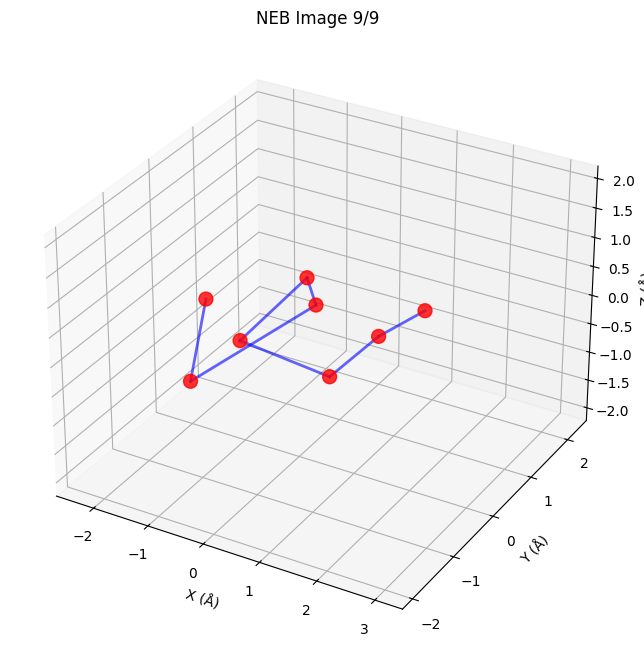

In [15]:
def create_neb_animation(neb_images, save_path='neb_animation.gif'):
    """
    Create an animated GIF showing the reaction progression
    """
    from matplotlib.animation import FuncAnimation
    
    num_images, num_atoms, _ = neb_images.shape
    
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # Set up the plot limits
    all_coords = neb_images.reshape(-1, 3)
    margin = 1.0
    ax.set_xlim([all_coords[:, 0].min() - margin, all_coords[:, 0].max() + margin])
    ax.set_ylim([all_coords[:, 1].min() - margin, all_coords[:, 1].max() + margin])
    ax.set_zlim([all_coords[:, 2].min() - margin, all_coords[:, 2].max() + margin])
    
    def animate(frame):
        ax.clear()
        ax.set_xlim([all_coords[:, 0].min() - margin, all_coords[:, 0].max() + margin])
        ax.set_ylim([all_coords[:, 1].min() - margin, all_coords[:, 1].max() + margin])
        ax.set_zlim([all_coords[:, 2].min() - margin, all_coords[:, 2].max() + margin])
        
        positions = neb_images[frame]
        
        # Plot current frame
        ax.scatter(positions[:, 0], positions[:, 1], positions[:, 2], 
                  c='red', s=100, alpha=0.8)
        
        # Connect atoms with bonds
        for atom_idx in range(num_atoms-1):
            ax.plot([positions[atom_idx, 0], positions[atom_idx+1, 0]],
                   [positions[atom_idx, 1], positions[atom_idx+1, 1]], 
                   [positions[atom_idx, 2], positions[atom_idx+1, 2]],
                   'b-', alpha=0.6, linewidth=2)
        
        ax.set_xlabel('X (Å)')
        ax.set_ylabel('Y (Å)')
        ax.set_zlabel('Z (Å)')
        ax.set_title(f'NEB Image {frame}/{num_images-1}')
    
    anim = FuncAnimation(fig, animate, frames=num_images, interval=500, repeat=True)
    anim.save(save_path, writer='pillow', fps=2)
    plt.show()
    
    return anim

# Create animation
anim = create_neb_animation(neb_images)

Most interesting reactions for visualization:
1. Index 12: [o:1]1[c:2]([H:6])[n:3][c:4]([H:7])[n:5]1>>[C:4](#[N:5])[H:7].[O:1]=[C:2]=[N:3][H:6]
   Avg displacement: 1.504 Å
   Atoms: 7, Images: 10

2. Index 16: [O:1]([c:2]1[n:3][o:4][c:5]([H:8])[n:6]1)[H:7]>>[C:5](#[N:6])[H:8].[O:1]([C:2]1=[N:3][O:4]1)[H:7]
   Avg displacement: 1.477 Å
   Atoms: 8, Images: 10

3. Index 48: [n:1]1([H:6])[c:2]([H:7])[n:3][n:4][c:5]1[H:8]>>[C:2](#[N:3])[H:7].[N:1](=[C:5]=[N:4][H:8])[H:6]
   Avg displacement: 1.277 Å
   Atoms: 8, Images: 10

4. Index 70: [O:1]([c+:2]1[n-:3][c:4]([H:8])[n:5][n:6]1[H:9])[H:7]>>[O:1]([C:2]([N+:3]#[C:4][H:8])[N:6]([N-:5])[H:9])[H:7]
   Avg displacement: 1.251 Å
   Atoms: 9, Images: 10

5. Index 55: [n:1]1([H:6])[c:2]([H:7])[n:3][c:4]([H:8])[n:5]1>>[C:2](#[N:3])[H:7].[N-:1]([N+:5]#[C:4][H:8])[H:6]
   Avg displacement: 1.232 Å
   Atoms: 8, Images: 10

Using reaction 12 for visualization
Saved 10 XYZ files to neb_snapshots/


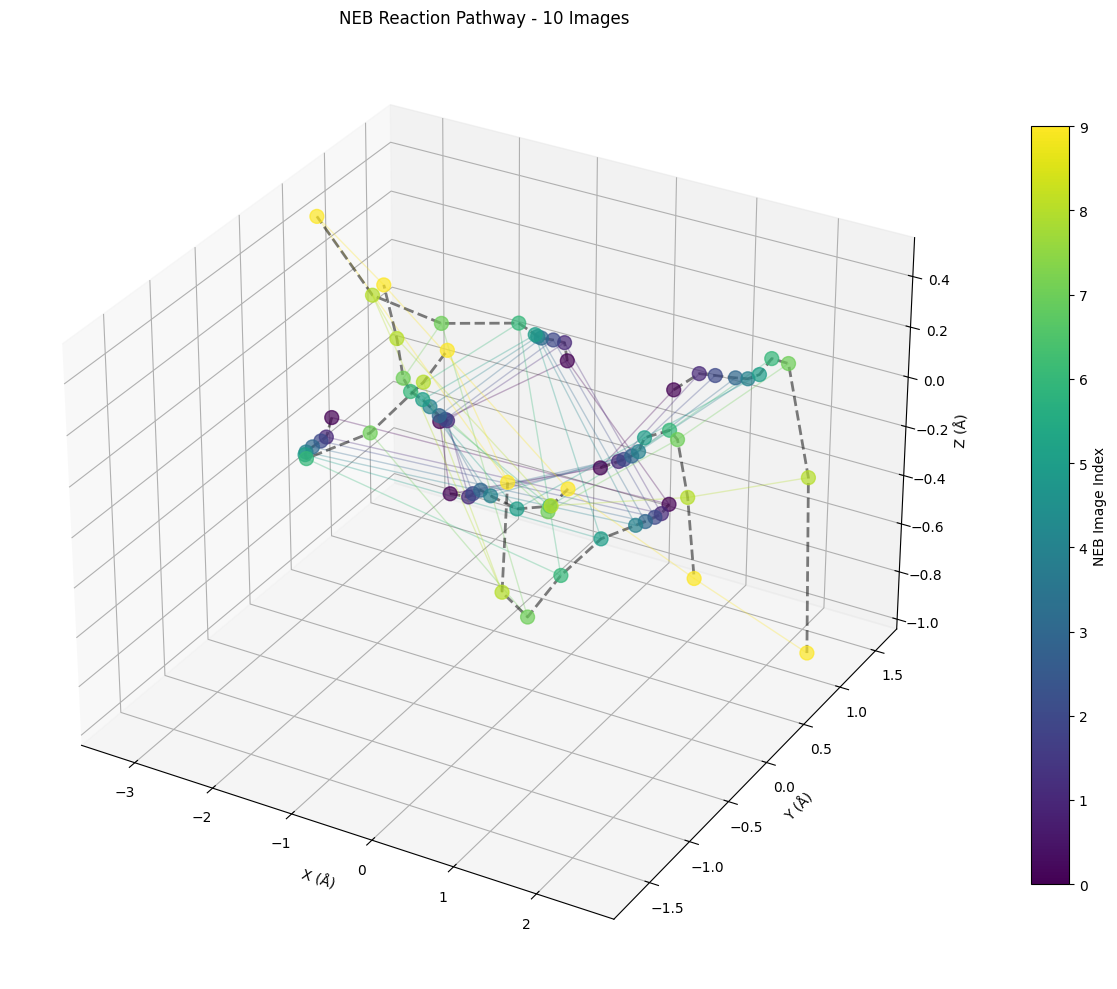

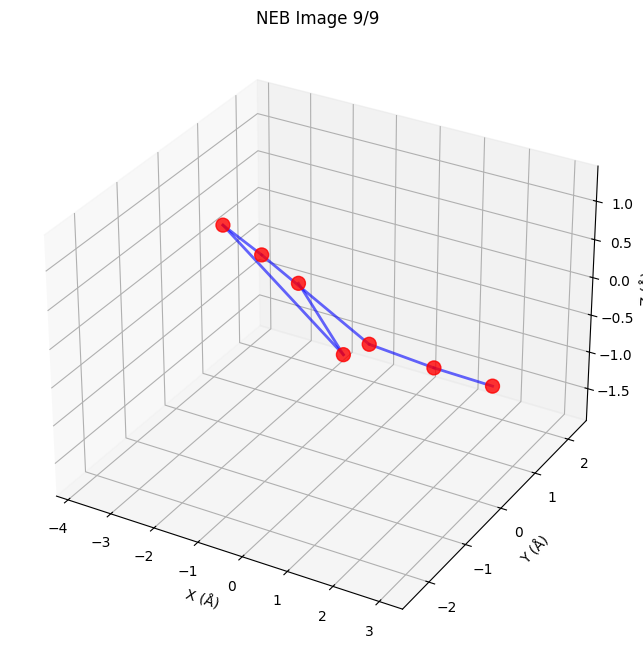

In [16]:
def find_interesting_reaction(data, min_displacement=0.5):
    """
    Find reactions with significant atomic movement for better visualization
    """
    interesting_reactions = []
    
    for idx, reaction in enumerate(data[:100]):  # Check first 100
        if hasattr(reaction, 'pos_N_3_I'):
            pos = reaction.pos_N_3_I.numpy()
            num_atoms, _, num_images = pos.shape
            
            # Calculate total displacement for each atom
            total_displacement = 0
            for atom_idx in range(num_atoms):
                start_pos = pos[atom_idx, :, 0]
                end_pos = pos[atom_idx, :, -1]
                displacement = np.linalg.norm(end_pos - start_pos)
                total_displacement += displacement
            
            avg_displacement = total_displacement / num_atoms
            
            if avg_displacement > min_displacement:
                interesting_reactions.append({
                    'idx': idx,
                    'smiles': reaction.smiles,
                    'avg_displacement': avg_displacement,
                    'num_atoms': num_atoms,
                    'num_images': num_images
                })
    
    # Sort by displacement
    interesting_reactions.sort(key=lambda x: x['avg_displacement'], reverse=True)
    
    print("Most interesting reactions for visualization:")
    for i, rxn in enumerate(interesting_reactions[:5]):
        print(f"{i+1}. Index {rxn['idx']}: {rxn['smiles']}")
        print(f"   Avg displacement: {rxn['avg_displacement']:.3f} Å")
        print(f"   Atoms: {rxn['num_atoms']}, Images: {rxn['num_images']}")
        print()
    
    return interesting_reactions

# Find good reactions for visualization
interesting = find_interesting_reaction(data)

# Use the most interesting one
if interesting:
    best_idx = interesting[0]['idx']
    print(f"Using reaction {best_idx} for visualization")
    reaction_data = data[best_idx]
    neb_images = reaction_data.pos_N_3_I.numpy().transpose(2, 0, 1)
    
    # Create all visualizations
    fig, ax = plot_neb_trajectory_3d(neb_images)
    save_individual_neb_images(neb_images, reaction_data)
    anim = create_neb_animation(neb_images)

In [19]:
from rdkit import Chem
import re

def strip_atom_mapping(smiles):
    # Remove atom mapping numbers, e.g. [O:1] -> [O]
    return re.sub(r'\:([0-9]+)', '', smiles)

def get_elements_from_smiles(smiles):
    # If reaction SMILES, take first reactant
    if '>>' in smiles:
        reactants = smiles.split('>>')[0]
        # If multiple reactants, take the first one
        reactant = reactants.split('.')[
            0] if '.' in reactants else reactants
    else:
        reactant = smiles
    reactant = strip_atom_mapping(reactant)
    mol = Chem.MolFromSmiles(reactant)
    if mol is None:
        raise ValueError("Invalid SMILES string after stripping atom mapping")
    return [atom.GetSymbol() for atom in mol.GetAtoms()]

# Example usage:
elements = get_elements_from_smiles(reaction_data.smiles)
print(elements)

# elements is the list from get_elements_from_smiles
num_atoms = neb_images.shape[1]
num_hydrogens = num_atoms - len(elements)
elements_with_h = elements + ['H'] * num_hydrogens
print(elements_with_h)

['O', 'C', 'N', 'C', 'N']
['O', 'C', 'N', 'C', 'N', 'H', 'H']


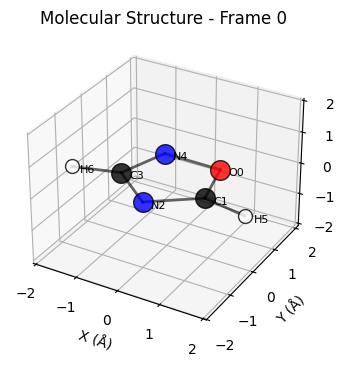

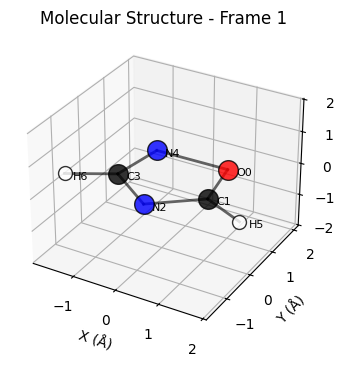

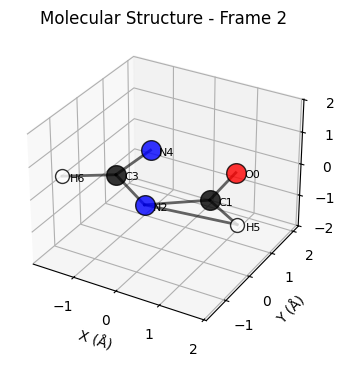

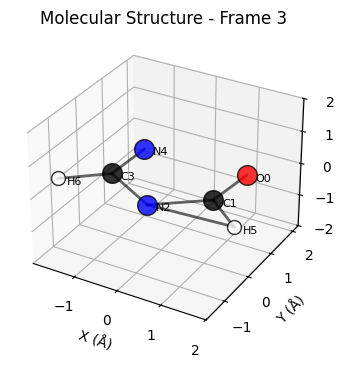

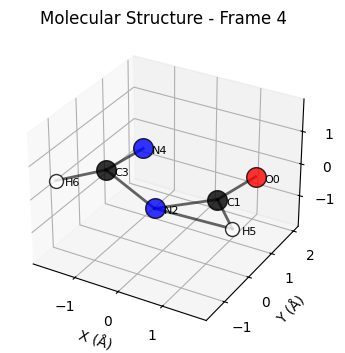

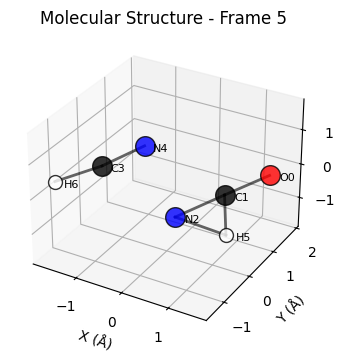

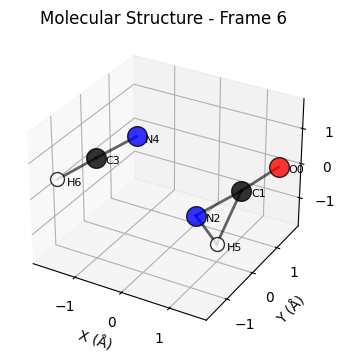

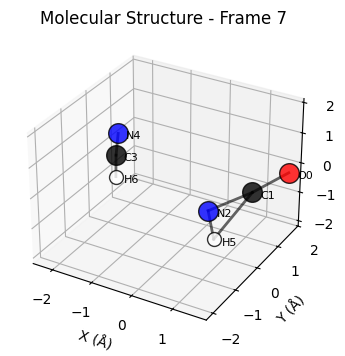

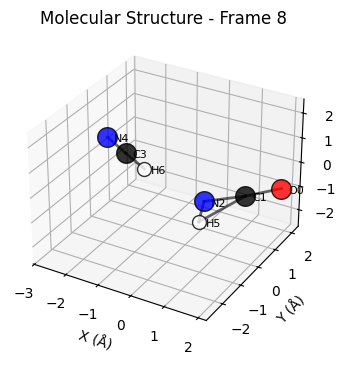

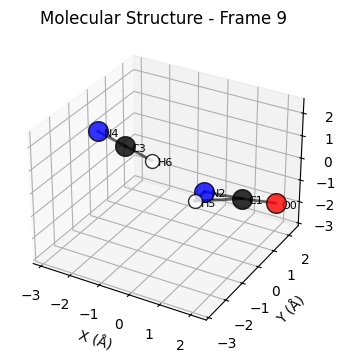

In [22]:
def plot_molecular_structure(neb_images, elements, frame_idx=0, 
                           atomic_colors=None, save_path=None):
    """
    Plot single molecular structure with proper atomic colors
    """
    if atomic_colors is None:
        # Standard CPK colors
        atomic_colors = {
            'H': 'white', 'C': 'black', 'N': 'blue', 'O': 'red', 
            'S': 'yellow', 'P': 'orange', 'F': 'lightgreen',
            'Cl': 'green', 'Br': 'darkred', 'I': 'purple'
        }
    
    fig = plt.figure(figsize=(6, 4))
    ax = fig.add_subplot(111, projection='3d')
    
    positions = neb_images[frame_idx]
    
    # Plot atoms
    for i, (pos, element) in enumerate(zip(positions, elements)):
        color = atomic_colors.get(element, 'gray')
        size = 200 if element != 'H' else 100  # Smaller for hydrogen
        ax.scatter(pos[0], pos[1], pos[2], 
                  c=color, s=size, alpha=0.8, 
                  edgecolors='black', linewidth=1)
        
        # Add atom labels
        # Offset label to the side (e.g., along +x direction)
        offset = 0.2  # adjust as needed for clarity
        ax.text(pos[0] + offset, pos[1], pos[2], f'{element}{i}', 
            fontsize=8, ha='left', va='center')
    
    # Draw bonds (simple distance-based)
    for i in range(len(positions)):
        for j in range(i+1, len(positions)):
            dist = np.linalg.norm(positions[i] - positions[j])
            # Typical bond lengths (adjust as needed)
            max_bond_length = 2.0  # Angstroms
            if dist < max_bond_length:
                ax.plot([positions[i][0], positions[j][0]],
                       [positions[i][1], positions[j][1]],
                       [positions[i][2], positions[j][2]], 
                       'k-', alpha=0.6, linewidth=2)
    
    ax.set_xlabel('X (Å)')
    ax.set_ylabel('Y (Å)')
    ax.set_zlabel('Z (Å)')
    ax.set_title(f'Molecular Structure - Frame {frame_idx}')
    
    # Equal aspect ratio
    max_range = np.array([positions[:,0].max()-positions[:,0].min(),
                         positions[:,1].max()-positions[:,1].min(),
                         positions[:,2].max()-positions[:,2].min()]).max() / 2.0
    mid_x = (positions[:,0].max()+positions[:,0].min()) * 0.5
    mid_y = (positions[:,1].max()+positions[:,1].min()) * 0.5
    mid_z = (positions[:,2].max()+positions[:,2].min()) * 0.5
    ax.set_xlim(mid_x - max_range, mid_x + max_range)
    ax.set_ylim(mid_y - max_range, mid_y + max_range)
    ax.set_zlim(mid_z - max_range, mid_z + max_range)
    
    # if save_path:
        # plt.savefig(save_path, dpi=300, bbox_inches='tight')
    
    plt.show()
    return fig, ax

# Usage
for i in range(len(neb_images)):
    plot_molecular_structure(neb_images, elements_with_h, frame_idx=i)

In [ ]:
with open('data_inr.pkl', 'rb') as f:
    data_inr = pickle.load(f)


In [ ]:
print("Data First Entry:", data_inr[1])
print("Data Length:", len(data_inr))

Data First Entry: Data(edge_index=[2, 14], pos=[7, 3, 10], atom_type=[7], r_feat=[7, 6], p_feat=[7, 6], r_edge_index=[2, 14], p_edge_index=[2, 10], edge_type=[14], rdmol=[2], smiles='[o:1]1[c:2]([H:6])[n:3][n:4][c:5]1[H:7]>>[N:3]#[N:4].[O+:1](=[C-:2][H:6])[C:5][H:7]', r_index_to_mapnum=[7], p_index_to_mapnum=[7], mapnum_to_r_index=[7], mapnum_to_p_index=[7], augmented=False, rxn_index='rxn2092')
Data Length: 9847


In [ ]:
with open('feat_dict_inr.pkl', 'rb') as f:
    feat_dict_inr = pickle.load(f)

In [ ]:
print("Feature Dictionary Length:", len(feat_dict_inr))
feat_dict_inr

Feature Dictionary Length: 6


{'GetIsAromatic': {True: 0, False: 1},
 'GetFormalCharge': {0: 0, 1: 1, -1: 2},
 'GetHybridization': {rdkit.Chem.rdchem.HybridizationType(3): 0,
  rdkit.Chem.rdchem.HybridizationType(1): 1,
  rdkit.Chem.rdchem.HybridizationType(2): 2,
  rdkit.Chem.rdchem.HybridizationType(4): 3},
 'GetTotalValence': {2: 0, 4: 1, 3: 2, 1: 3, 0: 4},
 'GetTotalDegree': {2: 0, 3: 1, 1: 2, 4: 3, 0: 4},
 'IsInRing': {True: 0, False: 1}}

In [ ]:
import numpy as np

def get_sinusoidal_embeddings(seq_len, d_model):
	position = np.arange(seq_len)[:,np.newaxis] # creates vector for each token position and converts shape for matrix ops
	print(position)
	div_term = np.exp(np.arange(0, d_model, 2) * -np.log(10000.0) / d_model) # creates divisor term of sinusoidal formula
	print(div_term)
	
	embeddings = np.zeros((seq_len, d_model)) # creates empty embedding matrix
	embeddings[:, 0::2] = np.sin(position * div_term) # slices all even dims
	embeddings[:, 1::2] = np.cos(position * div_term) # slices all odd dims
	
	return embeddings

In [ ]:
get_sinusoidal_embeddings(10, 16)

[[0]
 [1]
 [2]
 [3]
 [4]
 [5]
 [6]
 [7]
 [8]
 [9]]
[1.00000000e+00 3.16227766e-01 1.00000000e-01 3.16227766e-02
 1.00000000e-02 3.16227766e-03 1.00000000e-03 3.16227766e-04]


array([[ 0.00000000e+00,  1.00000000e+00,  0.00000000e+00,
         1.00000000e+00,  0.00000000e+00,  1.00000000e+00,
         0.00000000e+00,  1.00000000e+00,  0.00000000e+00,
         1.00000000e+00,  0.00000000e+00,  1.00000000e+00,
         0.00000000e+00,  1.00000000e+00,  0.00000000e+00,
         1.00000000e+00],
       [ 8.41470985e-01,  5.40302306e-01,  3.10983593e-01,
         9.50415280e-01,  9.98334166e-02,  9.95004165e-01,
         3.16175064e-02,  9.99500042e-01,  9.99983333e-03,
         9.99950000e-01,  3.16227239e-03,  9.99995000e-01,
         9.99999833e-04,  9.99999500e-01,  3.16227761e-04,
         9.99999950e-01],
       [ 9.09297427e-01, -4.16146837e-01,  5.91127117e-01,
         8.06578410e-01,  1.98669331e-01,  9.80066578e-01,
         6.32033979e-02,  9.98000667e-01,  1.99986667e-02,
         9.99800007e-01,  6.32451316e-03,  9.99980000e-01,
         1.99999867e-03,  9.99998000e-01,  6.32455490e-04,
         9.99999800e-01],
       [ 1.41120008e-01, -9.89992497e

In [4]:
import torch

a = torch.tensor([1, 2, 3])
b = torch.tensor([4, 5, 6])
c = torch.tensor([7, 8, 9])

result = torch.cat([a, b, c])
print(result)



a = torch.tensor([[1, 2, 3], [4, 5, 6]])
b = torch.tensor([[7, 8, 9], [10, 11, 12]])

result = torch.stack([a, b], dim=0)
print(result)


tensor([1, 2, 3, 4, 5, 6, 7, 8, 9])
tensor([[[ 1,  2,  3],
         [ 4,  5,  6]],

        [[ 7,  8,  9],
         [10, 11, 12]]])


In [2]:
# Load data.pkl
with open('data_inr.pkl', 'rb') as f:
    data = pickle.load(f)

# Load data.pkl
with open('splits/split_inr.pkl', 'rb') as f:
    split = pickle.load(f)

# Load feat_dict.pkl
with open('feat_dict_inr.pkl', 'rb') as f:
    feat_dict = pickle.load(f)

# Display types and basic info
type(data), type(split), type(feat_dict), len(data) if hasattr(data, '__len__') else None, len(split) if hasattr(split, '__len__') else None, len(feat_dict) if hasattr(feat_dict, '__len__') else None

(list, dict, dict, 9847, 3, 6)

In [3]:
print("Data:", data[1])
print("Feature Dictionary:", feat_dict)
print(data[1].pos_N_3_I.shape)

Data: Data(edge_index=[2, 14], rxn_idx='rxn2092', ts_idx=4, atom_type_N=[7], r_feat_N_Z=[7, 21], p_feat_N_Z=[7, 21], pos_N_3_I=[7, 3, 10], r_edge_index=[2, 14], p_edge_index=[2, 10], edge_type=[14], rdmol=[2], smiles='[o:1]1[c:2]([H:6])[n:3][n:4][c:5]1[H:7]>>[N:3]#[N:4].[O+:1](=[C-:2][H:6])[C:5][H:7]', r_index_to_mapnum=[7], p_index_to_mapnum=[7], mapnum_to_r_index=[7], mapnum_to_p_index=[7])
Feature Dictionary: {'GetIsAromatic': {True: 0, False: 1}, 'GetFormalCharge': {0: 0, 1: 1, -1: 2}, 'GetHybridization': {rdkit.Chem.rdchem.HybridizationType(3): 0, rdkit.Chem.rdchem.HybridizationType(1): 1, rdkit.Chem.rdchem.HybridizationType(2): 2, rdkit.Chem.rdchem.HybridizationType(4): 3}, 'GetTotalValence': {2: 0, 4: 1, 3: 2, 1: 3, 0: 4}, 'GetTotalDegree': {2: 0, 3: 1, 1: 2, 4: 3, 0: 4}, 'IsInRing': {True: 0, False: 1}}
torch.Size([7, 3, 10])


In [5]:
def find_reactions_by_indices(data_file, data_indices):
    """
    Search for reactions by their rxn_idx in the dataset.
    
    Args:
        data_file: Path to the pickle file containing the dataset
        data_indices: List of reaction indices to search for (e.g., ["rxn2091"])
    """
    with open(data_file, "rb") as f:
        all_data = pickle.load(f)
    
    # Convert to set for faster lookup
    search_indices = set(data_indices)
    found_reactions = []
    
    # Iterate through all data objects
    for data in all_data:
        if hasattr(data, 'rxn_idx') and data.rxn_idx in search_indices:
            found_reactions.append(data)
            print(f"Found match: {data.rxn_idx}")
            print(f"  - TS index: {data.ts_idx}")
            print(f"  - SMILES: {data.smiles}")
            print(f"  - Atoms: {data.atom_type_N.shape[0]}")
            print(f"  - NEB images shape: {data.pos_N_3_I.shape}")
            print()
    
    if not found_reactions:
        print(f"No matches found for: {data_indices}")
    else:
        print(f"Total matches found: {len(found_reactions)}")
    
    return found_reactions

In [7]:
# Usage
matched_data = find_reactions_by_indices('data_inr.pkl', ["rxn2092"])

Found match: rxn2092
  - TS index: 4
  - SMILES: [o:1]1[c:2]([H:6])[n:3][n:4][c:5]1[H:7]>>[N:3]#[N:4].[O+:1](=[C-:2][H:6])[C:5][H:7]
  - Atoms: 7
  - NEB images shape: torch.Size([7, 3, 10])

Total matches found: 1
